In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit


In [2]:

# === Costanti note o da impostare ===
g = 9.81  # m/s²

l = 1.13  # lunghezza del pendolo, in metri (esempio)
sigma_l = 0.02 # non si vede dove è il punto di pivot, molto dubbio

d = 1.15  # distanza punto di sospensione - traguardo ottico (esempio) A CASO
sigma_d = 0.001

w = 0.019  # larghezza bandierina, in metri (esempio)
sigma_w = 0.001


In [3]:

# === Caricamento dati ===
# Supponiamo che il file sia un CSV con tre colonne: tempo, periodo T, tempo di transito t_T
# data = pd.read_csv('dati_pendolo.csv', header=None, names=["tempo", "periodo", "t_transito"])


In [4]:
# Per test: generazione dati fittizi

#data = pd.DataFrame({
#     "tempo": np.linspace(0, 20, 100),
#     "periodo": 2.0 + 0.01*np.random.randn(100),
#     "t_transito": 0.05 * np.exp(-0.1 * np.linspace(0, 20, 100)) + 0.005*np.random.randn(100)
# })

In [5]:
#df = pd.read_csv('data.txt', header=None, delim_whitespace=True)

# For txt file

In [6]:
import numpy as np
import pandas as pd

# Seed per riproducibilità
np.random.seed(42)

# Tempo: da 0 a 20 secondi, 100 punti
tempo = np.linspace(0, 20, 100)

# Periodo quasi costante con rumore minimo (non interessa molto per l'esponenziale)
periodo = 2.0 + 0.005 * np.random.randn(100)

# t_transito decresce chiaramente in modo esponenziale
# aumento valore iniziale (0.2) e costante di decadimento (0.3)
t_transito = 0.2 * np.exp(-0.3 * tempo) + 0.001 * np.random.randn(100)

# Costruzione del DataFrame
data = pd.DataFrame({
    "tempo": tempo,
    "periodo": periodo,
    "t_transito": t_transito
})


**Fit speed to find damping constant**

In [7]:
# === Calcolo v0 ===
data["v0"] = (w / data["t_transito"]) * (l / d)

In [8]:

# === Fit esponenziale v0(t) ===
def exp_decay(t, v0_0, lambda_):
    return v0_0 * np.exp(-lambda_ * t)

popt, pcov = curve_fit(exp_decay, data["tempo"], data["v0"], p0=[1.0, 0.1])
v0_0_fit, lambda_fit = popt
tau_fit = 1 / lambda_fit

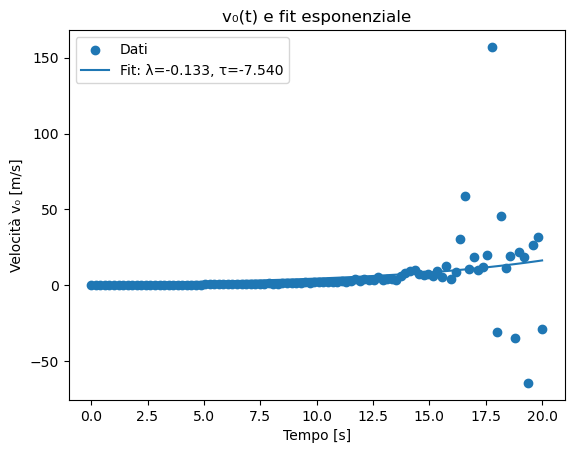

In [9]:
# === Plot v0 ===
plt.figure()
plt.scatter(data["tempo"], data["v0"], label="Dati")
plt.plot(data["tempo"], exp_decay(data["tempo"], *popt), label=f"Fit: λ={lambda_fit:.3f}, τ={tau_fit:.3f}")
plt.xlabel("Tempo [s]")
plt.ylabel("Velocità v₀ [m/s]")
plt.legend()
plt.title("v₀(t) e fit esponenziale")
plt.show()

**Fit theta**

In [10]:

# === Calcolo ampiezza θ₀ ===
data["theta0"] = np.arccos(1 - data["v0"]**2 / (2 * g * l))

# === Fit T(θ₀) ===
def T_series(theta, l_eff):
    return 2 * np.pi * np.sqrt(l_eff / g) * (1 + (1/16)*theta**2 + (11/3072)*theta**4)

popt_T, _ = curve_fit(T_series, data["theta0"], data["periodo"], p0=[l], maxfev=5000)

# === Plot T vs θ₀ ===
plt.figure()
plt.scatter(data["theta0"], data["periodo"], label="Dati")
theta_vals = np.linspace(0, max(data["theta0"]), 100)
plt.plot(theta_vals, T_series(theta_vals, *popt_T), label="Fit serie")
plt.xlabel("Ampiezza θ₀ [rad]")
plt.ylabel("Periodo T [s]")
plt.legend()
plt.title("Periodo T(θ₀) e fit teorico")
plt.show()


/usr/lib/python3/dist-packages/pandas/core/arraylike.py:396: RuntimeWarning: invalid value encountered in arccos
  result = getattr(ufunc, method)(*inputs, **kwargs)


RuntimeError: Optimal parameters not found: Number of calls to function has reached maxfev = 5000.

### Note

theta  = theta (0) e^{-t/tau}